# 🐙 Sous le capot de Kerdata

Ce carnet refait les trois actes du jeu avec le paquet `kerdata` : une colonie de 2 000 phoques, sans aucun nom. Tout est déterministe : même graine, même colonie.

*This notebook replays the three acts with the `kerdata` package (comments in French, code speaks for itself).*

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from kerdata import generate, unique_share, uniqueness_curve
from kerdata.catalog import QUASI_IDENTIFIERS
from kerdata.scenario import pick_target
from kerdata.synthesis import (
    ATTACK_COLUMNS,
    control_match_share,
    correlation_gap,
    exact_match_share,
    synthesize,
)
from kerdata.uniqueness import (
    age_band,
    candidates,
    coat_to_shade,
    distinct_loss,
    generalize,
    month_to_season,
    suppress_small_classes,
)

colonie = generate()  # 2 000 phoques, graine 29
colonie.head()

,pseudo,name,zone,sex,age,birth_month,coat,mark,temper,weight_kg,length_cm,secret
0,KD-86041,Goulven,ilot,F,6,11,tachete,aucun,paresseux,153,191,7
1,KD-656CE,Tifenn,greve,F,9,11,clair,aucun,solitaire,148,182,2
2,KD-806E1,Tanguy,greve,F,0,10,fonce,aucun,timide,56,112,11
3,KD-7A5C5,Gaïd,anse,F,10,12,tachete,aucun,timide,191,196,0
4,KD-13AAA,Alan,anse,F,19,11,clair,aucun,solitaire,228,182,11


## Acte I · Plus on pose de questions, plus chaque phoque devient unique

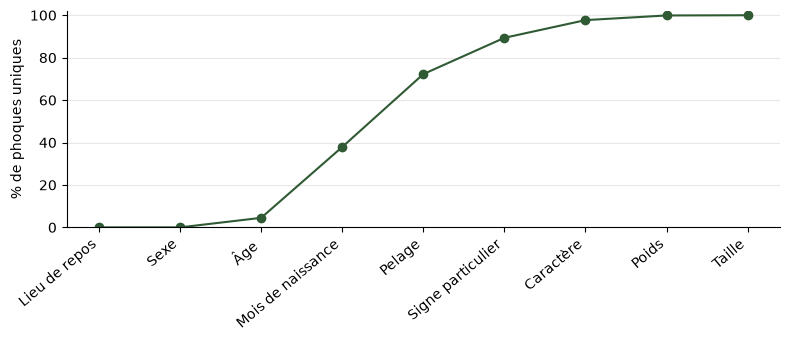

In [2]:
ordre = [a.key for a in QUASI_IDENTIFIERS]
libelles = {a.key: a.label.fr for a in QUASI_IDENTIFIERS}
courbe = pd.DataFrame(uniqueness_curve(colonie, ordre))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(range(1, len(courbe) + 1), courbe.unique_share * 100, marker="o", color="#2f5a34")
ax.set_xticks(
    range(1, len(courbe) + 1), [libelles[c] for c in courbe.column], rotation=40, ha="right"
)
ax.set_ylabel("% de phoques uniques")
ax.set_ylim(0, 102)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

In [3]:
# L'équivalent de Sweeney (code postal + sexe + date de naissance)
print(
    f"zone + sexe + âge + mois : {unique_share(colonie, ['zone', 'sex', 'age', 'birth_month']):.1%} de phoques uniques"
)

zone + sexe + âge + mois : 37.9% de phoques uniques


## Acte II · Le registre pseudonymisé résiste-t-il à 4 indices publics ?

In [4]:
cible = pick_target(colonie)
connu = {}
for colonne, valeur in cible.known.items():
    connu[colonne] = valeur
    print(f"{colonne:>8} = {valeur!s:<8} → {len(candidates(colonie, connu)):>5} suspects")

    zone = ilot     →   474 suspects
    coat = clair    →   107 suspects
    mark = tache    →    16 suspects
     age = 6        →     1 suspects


## Acte III · Le compromis risque / utilité

On généralise (âge par tranches de 5 ans, saison de naissance, pelage clair/foncé), on cache le signe particulier, puis on retire les phoques dont la classe compte moins de *k* membres.

In [5]:
attaque = list(ATTACK_COLUMNS)
flou = generalize(
    colonie, {"age": age_band(5), "birth_month": month_to_season, "coat": coat_to_shade}
).drop(columns="mark")
attaque = [c for c in attaque if c != "mark"]
lignes = []
for k in range(1, 11):
    publie, retires = suppress_small_classes(flou, attaque, k)
    lignes.append(
        {
            "k": k,
            "uniques": unique_share(publie, attaque),
            "conserves": len(publie) / len(colonie),
            "precision": 1 - distinct_loss(colonie, publie, attaque),
        }
    )
compromis = pd.DataFrame(lignes).set_index("k")
compromis.style.format("{:.1%}")

,uniques,conserves,precision
k,,,
1,8.3%,100.0%,59.2%
2,0.0%,91.6%,59.2%
3,0.0%,83.7%,59.2%
4,0.0%,76.1%,57.9%
5,0.0%,71.2%,56.2%
6,0.0%,63.9%,56.2%
7,0.0%,59.4%,55.6%
8,0.0%,53.4%,55.6%
9,0.0%,49.0%,54.9%


## Bonus · Données synthétiques : personne n'est recopié… mais des liens se perdent

In [6]:
synth = synthesize(colonie, [*attaque, "weight_kg"], seed=1)
print(
    f"sosies de vrais phoques uniques : {exact_match_share(colonie, synth, attaque):.1%} "
    f"(colonie témoin : {control_match_share(colonie, attaque, seed=30):.1%})"
)
print(
    f"écart de corrélation âge ↔ poids : {correlation_gap(colonie, synth, 'age', 'weight_kg'):.2f}"
)

sosies de vrais phoques uniques : 19.4% (colonie témoin : 20.8%)
écart de corrélation âge ↔ poids : 0.70
